In [77]:
import pandas as pd

chicago_taxi_dataset = pd.read_csv("https://download.mlcc.google.com/mledu-datasets/chicago_taxi_train.csv")
chicago_taxi_dataset.describe()

,TRIP_START_HOUR,TRIP_SECONDS,TRIP_MILES,TRIP_SPEED,PICKUP_CENSUS_TRACT,DROPOFF_CENSUS_TRACT,PICKUP_COMMUNITY_AREA,DROPOFF_COMMUNITY_AREA,FARE,TIPS,TIP_RATE,TOLLS,EXTRAS,TRIP_TOTAL
count,31694.000000,31694.000000,31694.000000,31694.000000,1.325900e+04,1.402300e+04,28477.000000,28199.000000,31694.000000,31694.000000,31694.000000,31694.000000,31694.000000,31694.000000
mean,14.185635,1319.796397,8.289463,20.256544,1.703153e+10,1.703140e+10,35.562138,25.550410,23.905210,3.246130,12.965785,0.002744,2.410468,29.755053
std,5.159454,928.932873,7.265672,11.110390,3.827747e+05,3.408106e+05,26.421367,20.349707,16.970022,4.284567,15.517765,0.164343,5.805087,23.145537
min,0.000000,60.000000,0.500000,4.000000,1.703102e+10,1.703101e+10,1.000000,1.000000,3.250000,0.000000,0.000000,0.000000,0.000000,3.250000
25%,10.500000,548.000000,1.720000,11.000000,1.703108e+10,1.703108e+10,8.000000,8.000000,9.000000,0.000000,0.000000,0.000000,0.000000,10.750000
50%,14.750000,1081.000000,5.920000,17.600000,1.703132e+10,1.703132e+10,32.000000,28.000000,18.750000,2.000000,12.200000,0.000000,0.000000,21.700000
75%,18.000000,1888.000000,14.500000,27.500000,1.703198e+10,1.703184e+10,59.000000,32.000000,38.750000,5.000000,20.800000,0.000000,4.000000,48.265000
max,23.750000,7140.000000,68.120000,64.800000,1.703198e+10,1.703198e+10,77.000000,77.000000,159.250000,60.000000,648.600000,27.000000,85.000000,248.500000


In [78]:
print("数据共有{}条\n".format(len(chicago_taxi_dataset.index)))

数据共有31694条



In [79]:
data = chicago_taxi_dataset.loc[:, ["TRIP_MILES", "TRIP_SECONDS", "FARE", "COMPANY", "PAYMENT_TYPE", "TIP_RATE"]]
data.describe(include="all")

,TRIP_MILES,TRIP_SECONDS,FARE,COMPANY,PAYMENT_TYPE,TIP_RATE
count,31694.000000,31694.000000,31694.000000,31694,31694,31694.000000
unique,NaN,NaN,NaN,31,7,NaN
top,NaN,NaN,NaN,Flash Cab,Credit Card,NaN
freq,NaN,NaN,NaN,7887,14142,NaN
mean,8.289463,1319.796397,23.905210,NaN,NaN,12.965785
std,7.265672,928.932873,16.970022,NaN,NaN,15.517765
min,0.500000,60.000000,3.250000,NaN,NaN,0.000000
25%,1.720000,548.000000,9.000000,NaN,NaN,0.000000
50%,5.920000,1081.000000,18.750000,NaN,NaN,12.200000
75%,14.500000,1888.000000,38.750000,NaN,NaN,20.800000


In [80]:
# 生成相关系数矩阵, 从而分析特征之间的相关性
data.corr(numeric_only=True)

,TRIP_MILES,TRIP_SECONDS,FARE,TIP_RATE
TRIP_MILES,1.000000,0.800855,0.975344,-0.049594
TRIP_SECONDS,0.800855,1.000000,0.830292,-0.084294
FARE,0.975344,0.830292,1.000000,-0.070979
TIP_RATE,-0.049594,-0.084294,-0.070979,1.000000


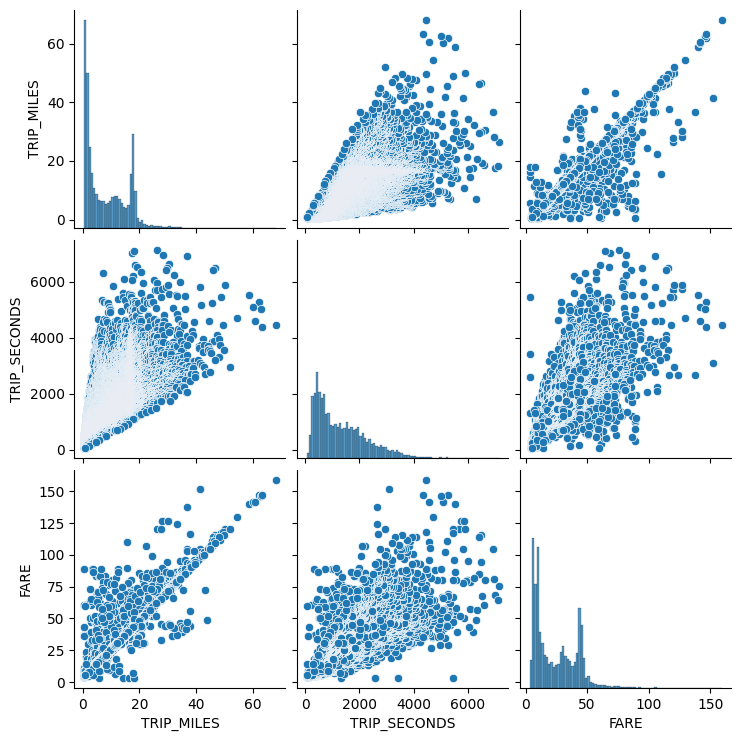

In [81]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.pairplot(data=data, vars=["TRIP_MILES", "TRIP_SECONDS", "FARE"])

# 定义线性回归模型

In [82]:
import numpy as np

In [83]:
class LinearRegression:
    def __init__(self, learning_rate=0.001, batch_size=50, epoch = 20):
        self.coefficients = None # 系数(权重)
        self.intercept = None    # 截距(偏差)
        self.learning_rate = learning_rate
        self.batch_size = batch_size
        self.epoch = epoch
        self.mse_history = [] # 记录每次迭代的MSE值, 用于后续分析模型的收敛情况
    
    def MSE(self, X, y):
        """计算均方误差

        Args:
            X (二维数组): 特征 n * m
            y (一维数组): 目标 n * 1

        Returns:
            一个值: 均方误差
        """
        n_samples = len(X)
        y_pred = self.predict(X)
        mse = np.mean((y_pred - y) ** 2)
        return mse
        
    def MSE_partial_weight_gradient(self, X, y):
        """计算MSE损失函数对权重的偏导数

        Args:
            X (二维数组): 特征 n * m
            y (一维数组): 目标 n * 1

        Returns:
            一维数组: MSE损失函数对每个权重的偏导数
        """
        n_samples = len(X) # n
        y_pred = self.predict(X)
        return (2 / n_samples) * X.T.dot(y_pred - y)
    
    def MSE_partial_bias_gradient(self, X, y):
        """计算MSE损失函数对偏差的偏导数

        Args:
            X (二维数组): 特征 n * m
            y (一维数组): 目标 n * 1

        Returns:
            一个值: MSE损失函数对偏差的偏导数
        """
        n_samples = len(X) # n
        y_pred = self.predict(X)
        return (2 / n_samples) * np.sum(y_pred - y)
    
    def fit(self, X, y):
        """梯度下降, 找到最好的权重和偏差

        Args:
            X (二维数组): 特征
            y (一维数组): 目标
        """
        # 1. 初始化权重和偏差
        n_samples, n_features = X.shape
        self.coefficients = np.zeros(n_features)
        self.intercept = 0
        
        indices = np.arange(n_samples) # 生成0,1,2,...,n的数组
        for _ in range(self.epoch):
            # 2. 计算MSE
            np.random.shuffle(indices) # 打乱顺序
            for i in range(0, n_samples, self.batch_size):
                batch_idx = indices[i:i+self.batch_size]
                X_batch = X[batch_idx]
                y_batch = y[batch_idx]
                
                # 3. 计算权重和偏差的梯度
                weight_gradient = self.MSE_partial_weight_gradient(X_batch, y_batch)
                bias_gradient = self.MSE_partial_bias_gradient(X_batch, y_batch)
                
                # 4. 更新权重和偏差
                self.coefficients -= self.learning_rate * weight_gradient
                self.intercept -= self.learning_rate * bias_gradient
            mse = self.MSE(X, y)
            self.mse_history.append(mse)
            
    def predict(self, X):
        return self.intercept + X.dot(self.coefficients)
    
    def plot_mse_history(self):
        plt.plot(range(1, self.epoch + 1), self.mse_history)
        plt.xlabel("Epoch")
        plt.ylabel("MSE")
        plt.title("MSE History")
        plt.show()

In [84]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()

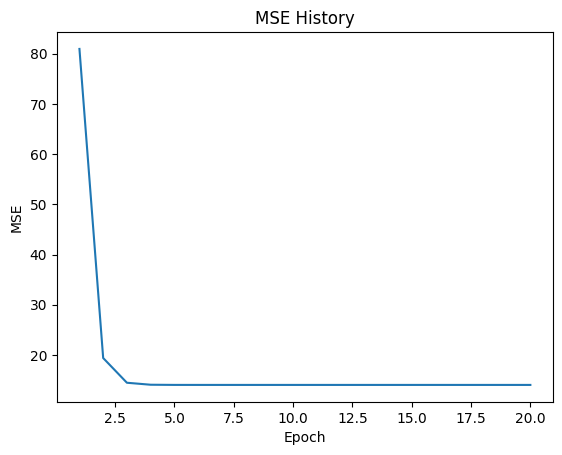

In [85]:
# 训练模型
# 1. 用TRIP_MILES单个特征训练
single_model = LinearRegression(learning_rate=0.001, batch_size=50, epoch=20)
X_single = data["TRIP_MILES"].values.reshape(-1, 1) # 转换为二维数组
X_single_scaled = scaler.fit_transform(X_single)
y = data["FARE"].values

single_model.fit(X_single_scaled, y)
single_model.plot_mse_history()

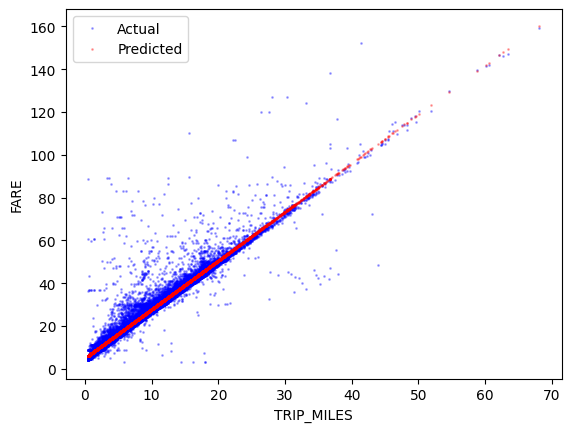

In [86]:
y_pred = single_model.predict(X_single_scaled)
plt.plot(X_single, y, 'b.', label='Actual', alpha=0.3, markersize=2)
plt.plot(X_single, y_pred, 'r.', label='Predicted', alpha=0.3, markersize=2)
plt.xlabel("TRIP_MILES")
plt.ylabel("FARE")
plt.legend()
plt.show()

In [87]:
# 2. 用TRIP_MILES和TRIP_MINUTES两个特征训练
X_double = data[["TRIP_MILES", "TRIP_SECONDS"]]
X_double["TRIP_MINUTES"] = X_double["TRIP_SECONDS"] / 60
X_double = X_double[["TRIP_MILES", "TRIP_MINUTES"]]

X_double_scaled = scaler.fit_transform(X_double)
X_double_scaled

array([[-0.7872022 ,  1.09934716],
       [-0.97851582, -0.26460499],
       [-0.96337589, -0.15802941],
       ...,
       [ 0.53960587, -0.68121863],
       [ 3.8965404 ,  0.77531433],
       [ 3.91030397,  0.77531433]], shape=(31694, 2))

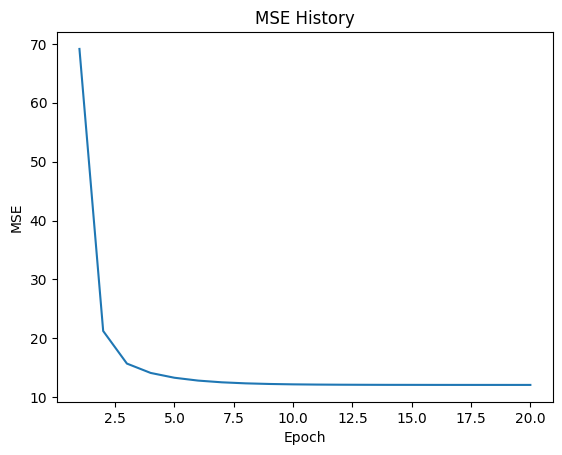

In [88]:
double_model = LinearRegression(learning_rate=0.001, batch_size=50, epoch=20)
double_model.fit(X_double_scaled, y)
double_model.plot_mse_history()

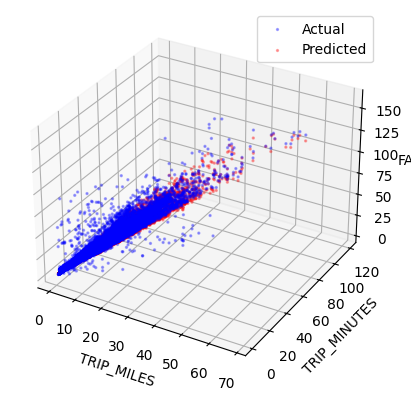

In [89]:
from mpl_toolkits.mplot3d import Axes3D
y_pred_double = double_model.predict(X_double_scaled)

fig = plt.figure()
ax = fig.add_subplot(projection='3d')

ax.scatter(X_double["TRIP_MILES"], X_double["TRIP_MINUTES"], y, 
           c='b', label='Actual', alpha=0.3, s=2)
ax.scatter(X_double["TRIP_MILES"], X_double["TRIP_MINUTES"], y_pred_double, 
           c='r', label='Predicted', alpha=0.3, s=2)

ax.set_xlabel("TRIP_MILES")
ax.set_ylabel("TRIP_MINUTES")
ax.set_zlabel("FARE")
ax.legend()
plt.show()


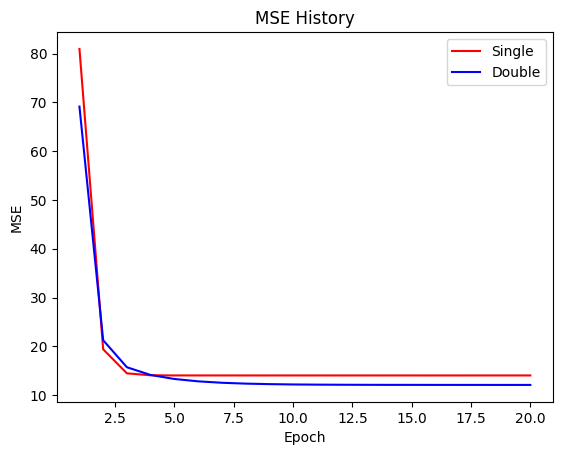

In [90]:
epoch = single_model.epoch
plt.plot(range(1, epoch + 1), single_model.mse_history, 'r', label="Single")
plt.plot(range(1, epoch + 1), double_model.mse_history, 'b', label="Double")
plt.xlabel("Epoch")
plt.ylabel("MSE")
plt.title("MSE History")
plt.legend()
plt.show()

In [91]:
y_predict = double_model.predict(X_double_scaled)
result = data.copy()
result["PRED_FARE"] = y_predict
result["TRIP_MINUTES"] = result["TRIP_SECONDS"] / 60
result = result[["TRIP_MILES", "TRIP_MINUTES", "FARE", "PRED_FARE"]]
result

,TRIP_MILES,TRIP_MINUTES,FARE,PRED_FARE
0,2.57,39.016667,31.99,14.973761
1,1.18,17.900000,9.75,8.919204
2,1.29,19.550000,10.25,9.395094
3,3.70,56.000000,23.75,19.867578
4,1.15,17.400000,10.00,8.781721
...,...,...,...,...
31689,13.06,12.316667,32.50,32.031778
31690,30.90,29.000000,44.50,70.597376
31691,12.21,11.450000,30.75,30.183246
31692,36.60,34.000000,41.75,82.868490


In [93]:
mse = np.mean((result["PRED_FARE"] - result["FARE"]) ** 2)
print("MSE:", mse)

MSE: 12.084357003543548
